In [8]:
import cv2
import pytesseract
import matplotlib.pyplot as plt

In [9]:
img = cv2.imread('images/original.png')

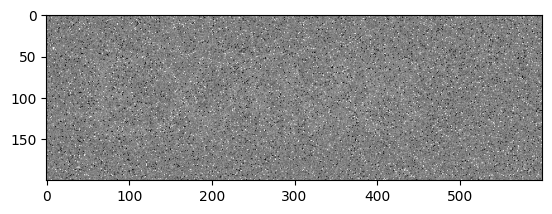

In [10]:
plt.imshow(img)

Detected Text: EXAMB



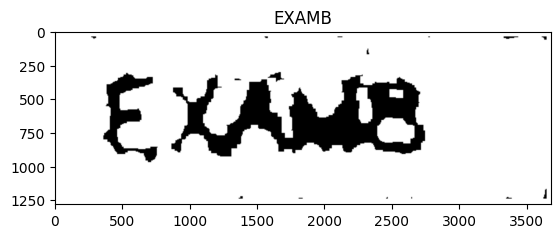

In [17]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blured_mediane = cv2.medianBlur(gray, 21)

_, thresh = cv2.threshold(blured_mediane,0,255,cv2.THRESH_BINARY + cv2.THRESH_OTSU)
threshold = cv2.bitwise_not(thresh)

k = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
dilate = cv2.dilate(threshold,k,iterations=2)

clean_image = cv2.morphologyEx(dilate, cv2.MORPH_OPEN, k)
cleaned_image_2 = cv2.resize(clean_image, None, fx=6, fy=6, interpolation=cv2.INTER_LINEAR)
cleaned = cv2.copyMakeBorder(cleaned_image_2, 40 , 40, 40, 40,cv2.BORDER_CONSTANT,value=255)



config = r'--oem 1 --psm 8 -c tessedit_char_whitelist=ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789'


text = pytesseract.image_to_string(cleaned, config=config)

print(f"Detected Text: {text}")


plt.imshow(cleaned, cmap="gray")
plt.title(f"{text.strip()}")
plt.savefig("results/output.png", bbox_inches="tight")
plt.show()